# Titanic Survival Prediction — End-to-End Machine Learning Project
*Week 4 — AI/ML Internship*

## 1. Project title
**Titanic Survival Prediction: an end-to-end classification system with a web app**

## 2. Problem statement
Given basic facts about a passenger (ticket class, sex, age, family aboard, fare, port of embarkation), predict whether the passenger survived the sinking of the Titanic.

## 3. Project objectives
1. Collect and clean a real-world dataset.
2. Explore it to find which factors relate to survival.
3. Build a leak-free preprocessing + feature-engineering pipeline.
4. Train, tune and compare at least three models using cross-validation.
5. Evaluate the chosen model honestly on a held-out test set.
6. Deliver a prediction system (command line + Streamlit web app).

## 4. Dataset collection
**Source:** the Titanic dataset from the `seaborn-data` repository (https://github.com/mwaskom/seaborn-data), saved locally as `data/titanic_raw.csv`. It has 891 passenger records and 15 columns. Only seven raw input columns are used (`pclass, sex, age, sibsp, parch, fare, embarked`); the others (`class, who, adult_male, deck, embark_town, alive, alone`) duplicate those fields or the target, or are mostly empty (`deck`).

In [1]:
import sys, json, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from pipeline import RAW_FEATURES, TARGET, build_pipeline, load_and_clean, add_features
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
%matplotlib inline

raw = pd.read_csv("../data/titanic_raw.csv")
print("Raw shape:", raw.shape)
display(raw.head())

Raw shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 5. Data cleaning

In [2]:
m = raw[RAW_FEATURES + [TARGET]].isnull().sum()
print("Missing values (used columns):"); display(m[m > 0].to_frame("missing").assign(percent=lambda d: (d.missing/len(raw)*100).round(1)))
print("Missing in dropped column 'deck':", raw["deck"].isnull().sum(), f"({raw['deck'].isnull().mean():.1%})")
df, n_dups = load_and_clean("../data/titanic_raw.csv")
print(f"Duplicate rows removed: {n_dups} -> clean dataset: {df.shape}")
df.to_csv("../data/titanic_cleaned.csv", index=False)

Missing values (used columns):


,missing,percent
age,177,19.9
embarked,2,0.2


Missing in dropped column 'deck': 688 (77.2%)
Duplicate rows removed: 111 -> clean dataset: (780, 8)


**Decisions.** `deck` (77% missing) is dropped. Duplicates are removed. The 177 missing ages and 2 missing ports are *not* filled here; imputation (median / most frequent) happens inside the model pipeline so it is learned from the training data only, which avoids data leakage. Fare outliers are real tickets, so they are kept and handled with a log transform.

## 6. Exploratory Data Analysis

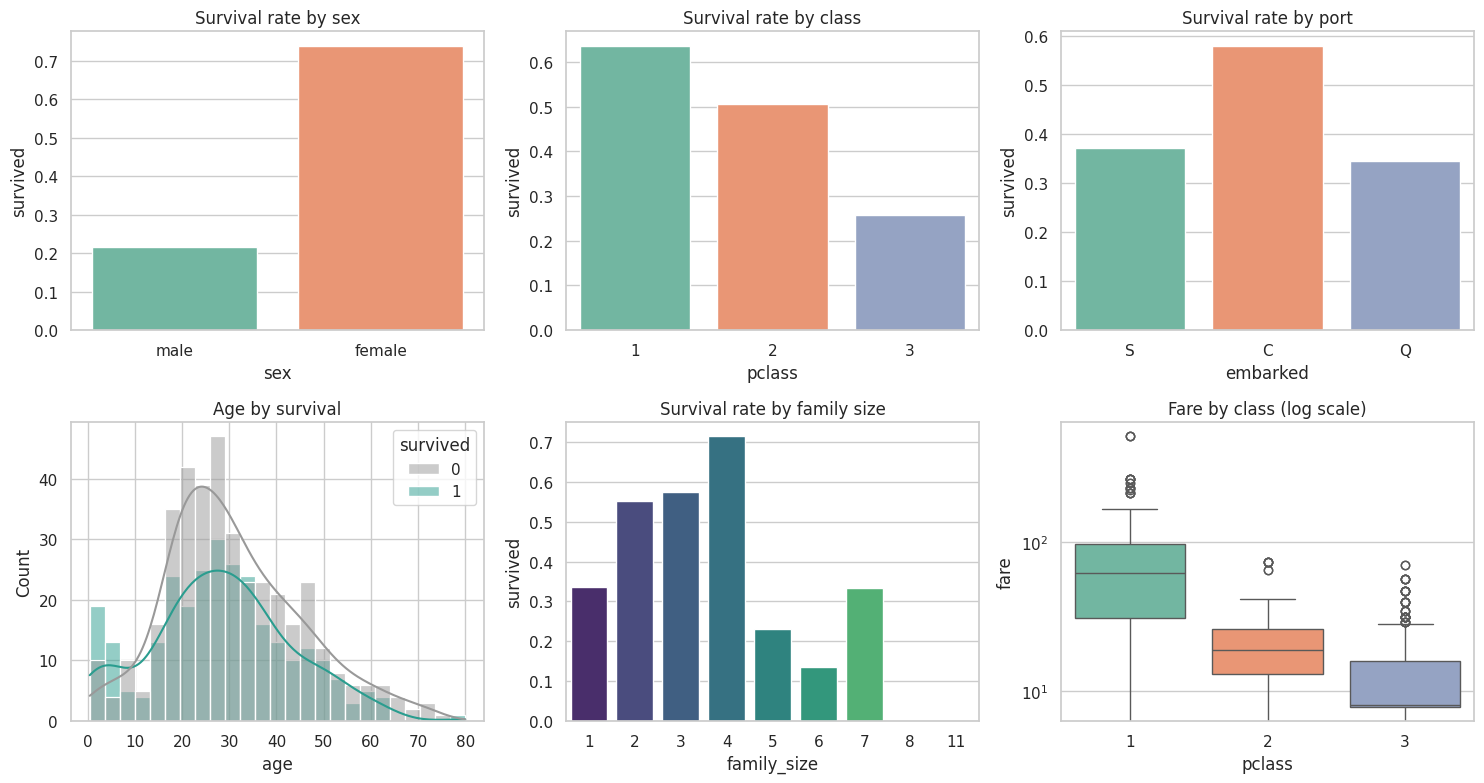

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
sns.barplot(data=df, x="sex", y="survived", ax=ax[0,0], palette="Set2", errorbar=None); ax[0,0].set_title("Survival rate by sex")
sns.barplot(data=df, x="pclass", y="survived", ax=ax[0,1], palette="Set2", errorbar=None); ax[0,1].set_title("Survival rate by class")
sns.barplot(data=df, x="embarked", y="survived", ax=ax[0,2], palette="Set2", errorbar=None); ax[0,2].set_title("Survival rate by port")
sns.histplot(data=df, x="age", hue="survived", bins=25, kde=True, ax=ax[1,0], palette=["#999999", "#2a9d8f"]); ax[1,0].set_title("Age by survival")
fs = (df.sibsp + df.parch + 1)
sns.barplot(x=fs, y=df["survived"], ax=ax[1,1], palette="viridis", errorbar=None); ax[1,1].set_title("Survival rate by family size"); ax[1,1].set_xlabel("family_size")
sns.boxplot(data=df, x="pclass", y="fare", ax=ax[1,2], palette="Set2"); ax[1,2].set_yscale("log"); ax[1,2].set_title("Fare by class (log scale)")
plt.tight_layout(); plt.savefig(FIG + "eda_overview.png", dpi=150); plt.show()

Overall survival rate: 41.3%


pclass,1,2,3
sex,,,
female,0.968,0.917,0.472
male,0.378,0.185,0.159


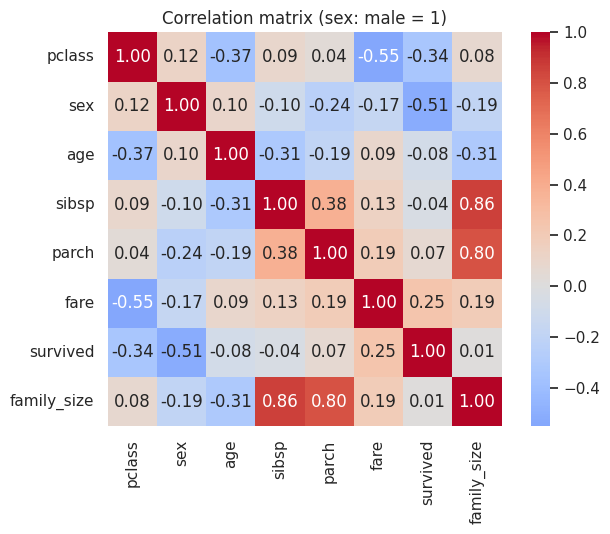

In [4]:
print("Overall survival rate: {:.1%}".format(df.survived.mean()))
display(df.pivot_table(values="survived", index="sex", columns="pclass", aggfunc="mean").round(3).rename_axis(columns="pclass"))
enc = df.assign(sex=(df.sex == "male").astype(int)).assign(family_size=fs)
corr = enc.drop(columns="embarked").corr()
plt.figure(figsize=(7, 5.5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (sex: male = 1)"); plt.tight_layout(); plt.savefig(FIG + "eda_correlation.png", dpi=150); plt.show()

## 7. Data preprocessing
Implemented as one scikit-learn pipeline (`src/pipeline.py`) so identical steps run in training and in the app:
- numeric (`age, sibsp, parch, family_size, fare_log`): median imputation → standard scaling
- categorical (`pclass, sex, embarked`): most-frequent imputation → one-hot encoding
- `is_alone` passes through unchanged

## 8. Feature engineering / selection
Three engineered features: `family_size = sibsp + parch + 1`, `is_alone`, and `fare_log = log(1 + fare)` (reduces fare skew). Feature selection is done by measuring importance after training (section 10 / 12) rather than discarding features beforehand, because the feature set is small (11 columns after encoding).

In [5]:
Xf = add_features(df[RAW_FEATURES])
display(Xf.head())
print("Fare skew before log:", round(df.fare.skew(), 2), "| after:", round(Xf.fare_log.skew(), 2))

,pclass,sex,age,sibsp,parch,embarked,family_size,is_alone,fare_log
0,3,male,22.0,1,0,S,2,0,2.110213
1,1,female,38.0,1,0,C,2,0,4.280593
2,3,female,26.0,0,0,S,1,1,2.188856
3,1,female,35.0,1,0,S,2,0,3.990834
4,3,male,35.0,0,0,S,1,1,2.202765


Fare skew before log: 4.56 | after: 0.45


## 9. Model training
Stratified 80/20 train/test split. Three models are tuned with 5-fold cross-validated `GridSearchCV` on the **training set only**, scored by ROC-AUC. The model is chosen from cross-validation results — the test set is not used for selection.

In [6]:
X, y = df[RAW_FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape, "| survival rate train/test:", round(y_train.mean(),3), round(y_test.mean(),3))
candidates = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=42), {"clf__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (RandomForestClassifier(random_state=42), {"clf__n_estimators": [200, 400], "clf__max_depth": [4, 6, 8], "clf__min_samples_leaf": [1, 3, 5]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42), {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.03, 0.1], "clf__max_depth": [2, 3]}),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
tuned, cv_scores = {}, {}
for name, (clf, grid) in candidates.items():
    gs = GridSearchCV(build_pipeline(clf), grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
    tuned[name], cv_scores[name] = gs.best_estimator_, gs.best_score_
    print(f"{name:20s} CV ROC-AUC = {gs.best_score_:.3f} | best params: { {k[5:]: v for k, v in gs.best_params_.items()} }")
best = max(cv_scores, key=cv_scores.get)
print("\nSelected model:", best)
assert best == json.load(open("../models/model_info.json"))["selected_model"], "notebook and train.py disagree"

Train: (624, 7) | Test: (156, 7) | survival rate train/test: 0.413 0.41


Logistic Regression  CV ROC-AUC = 0.831 | best params: {'C': 0.1}


Random Forest        CV ROC-AUC = 0.845 | best params: {'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 400}


Gradient Boosting    CV ROC-AUC = 0.854 | best params: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}

Selected model: Gradient Boosting


## 10. Model evaluation (held-out test set)

,cv_roc_auc,accuracy,precision,recall,f1,roc_auc
model,,,,,,
Logistic Regression,0.831,0.795,0.742,0.766,0.754,0.878
Random Forest,0.845,0.808,0.870,0.625,0.727,0.862
Gradient Boosting,0.854,0.821,0.860,0.672,0.754,0.881


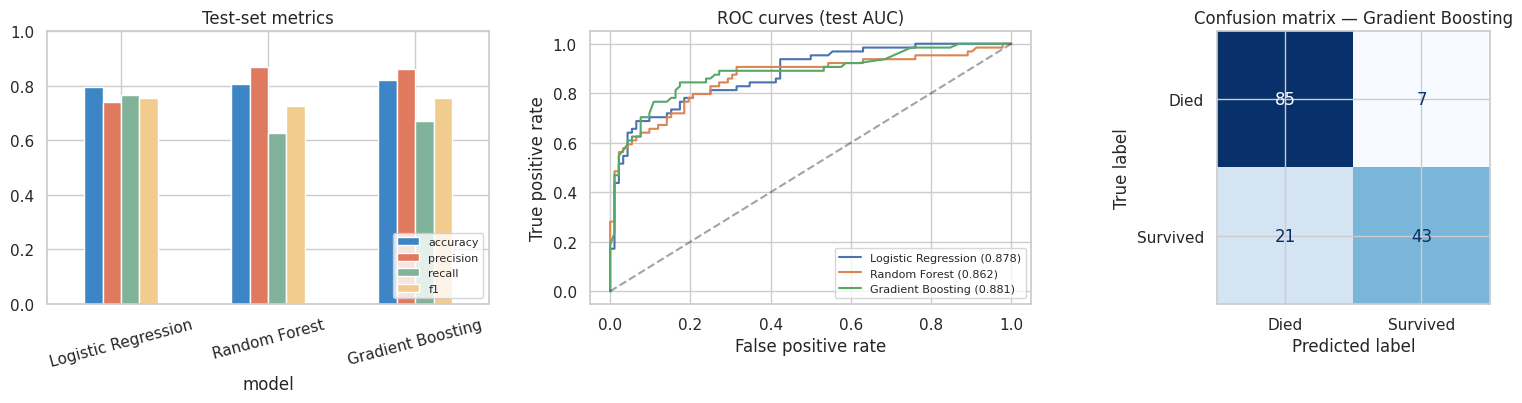

              precision    recall  f1-score   support

        Died       0.80      0.92      0.86        92
    Survived       0.86      0.67      0.75        64

    accuracy                           0.82       156
   macro avg       0.83      0.80      0.81       156
weighted avg       0.83      0.82      0.82       156

TN=85 FP=7 FN=21 TP=43


In [7]:
rows = []
for n, m in tuned.items():
    p, pr = m.predict(X_test), m.predict_proba(X_test)[:, 1]
    rows.append({"model": n, "cv_roc_auc": cv_scores[n], "accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                 "recall": recall_score(y_test, p), "f1": f1_score(y_test, p), "roc_auc": roc_auc_score(y_test, pr)})
res = pd.DataFrame(rows).set_index("model").round(3)
display(res)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
res[["accuracy", "precision", "recall", "f1"]].plot.bar(ax=ax[0], rot=15, color=["#3d85c6", "#e07a5f", "#81b29a", "#f2cc8f"]); ax[0].set_ylim(0, 1); ax[0].set_title("Test-set metrics"); ax[0].legend(loc="lower right", fontsize=8)
for n, m in tuned.items():
    f, t, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1]); ax[1].plot(f, t, label=f"{n} ({res.loc[n,'roc_auc']:.3f})")
ax[1].plot([0, 1], [0, 1], "k--", alpha=.4); ax[1].set_title("ROC curves (test AUC)"); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend(fontsize=8)
ConfusionMatrixDisplay(confusion_matrix(y_test, tuned[best].predict(X_test)), display_labels=["Died", "Survived"]).plot(ax=ax[2], cmap="Blues", colorbar=False); ax[2].set_title(f"Confusion matrix — {best}")
plt.tight_layout(); plt.savefig(FIG + "model_evaluation.png", dpi=150); plt.show()
print(classification_report(y_test, tuned[best].predict(X_test), target_names=["Died", "Survived"]))
tn, fp, fn, tp = confusion_matrix(y_test, tuned[best].predict(X_test)).ravel(); print(f"TN={tn} FP={fp} FN={fn} TP={tp}")

## 11. Prediction system
The saved pipeline accepts **raw** passenger fields, so no manual preprocessing is needed. It is used by `src/predict.py` (command line) and `app.py` (Streamlit).

In [8]:
from predict import predict_passenger
demo = [("1st-class woman, 29, Cherbourg", dict(pclass=1, sex="female", age=29, sibsp=0, parch=0, fare=80, embarked="C")),
        ("3rd-class man, 25, alone",         dict(pclass=3, sex="male",   age=25, sibsp=0, parch=0, fare=7.5, embarked="S")),
        ("2nd-class boy, 8, with family",    dict(pclass=2, sex="male",   age=8,  sibsp=1, parch=2, fare=30, embarked="S")),
        ("3rd-class woman, 22, large family",dict(pclass=3, sex="female", age=22, sibsp=3, parch=2, fare=25, embarked="S")),
        ("3rd-class man, age unknown",       dict(pclass=3, sex="male",   age=np.nan, sibsp=0, parch=0, fare=8, embarked="S"))]
out = pd.DataFrame([{"passenger": d, **predict_passenger(**k)} for d, k in demo])
out["survival_probability"] = out["survival_probability"].round(3); display(out)

,passenger,survived,survival_probability
0,"1st-class woman, 29, Cherbourg",True,0.951
1,"3rd-class man, 25, alone",False,0.137
2,"2nd-class boy, 8, with family",True,0.607
3,"3rd-class woman, 22, large family",False,0.156
4,"3rd-class man, age unknown",False,0.156


## 12. Results & analysis

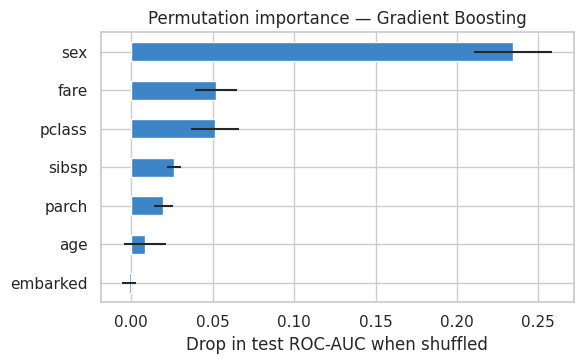

,importance
sex,0.235
fare,0.052
pclass,0.052
sibsp,0.026
parch,0.020
age,0.008
embarked,-0.001


In [9]:
# Which inputs matter? Permutation importance on the test set, using the train-only tuned model (raw features)
pi = permutation_importance(tuned[best], X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=42)
imp = pd.Series(pi.importances_mean, index=RAW_FEATURES).sort_values()
plt.figure(figsize=(6, 3.8)); imp.plot.barh(xerr=pd.Series(pi.importances_std, index=RAW_FEATURES)[imp.index], color="#3d85c6")
plt.xlabel("Drop in test ROC-AUC when shuffled"); plt.title(f"Permutation importance — {best}")
plt.tight_layout(); plt.savefig(FIG + "feature_importance.png", dpi=150); plt.show()
display(imp.sort_values(ascending=False).round(3).to_frame("importance"))

In [10]:
# Error analysis: accuracy by group on the test set
t = X_test.copy(); t["actual"] = y_test; t["pred"] = tuned[best].predict(X_test); t["correct"] = (t.actual == t.pred)
print("Accuracy by sex:");    display(t.groupby("sex").correct.agg(["mean", "count"]).round(3))
print("Accuracy by class:");  display(t.groupby("pclass").correct.agg(["mean", "count"]).round(3))
print("Where the model errs (counts of actual survivors predicted as died, by sex):")
display(t[(t.actual == 1) & (t.pred == 0)].groupby("sex").size().to_frame("missed_survivors"))

Accuracy by sex:


,mean,count
sex,,
female,0.783,60
male,0.844,96


Accuracy by class:


,mean,count
pclass,,
1,0.780,50
2,0.967,30
3,0.789,76


Where the model errs (counts of actual survivors predicted as died, by sex):


,missed_survivors
sex,
female,7
male,14
